# DBSCAN Cosine - versi Kaggle (hemat memori, data penuh)

**Cara pakai di Kaggle**
1. Upload `diabetes_012_health_indicators_BRFSS2015.csv` (*Datasets -> New Dataset*), lalu klik **Add Input** di notebook ini. Path-nya dicari otomatis, tidak perlu diketik.
2. Accelerator pilih **None** (CPU). Internet tidak perlu. DBSCAN ini tidak memakai GPU.
3. Jalankan semua sel. Supaya file hasil tersimpan di tab **Output**, pakai *Save Version -> Save & Run All (Commit)*.
4. Download `hasil_dbscan_cosine.zip` dari tab Output, ekstrak ke folder `outputDBSCAN` di Drive (di sebelah folder `outputKmeans`).

**Apa yang berubah dibanding versi Colab**
- DBSCAN sekarang jalan di **seluruh data (208.858 baris)**, bukan sampel 10.000. Atur lewat `N_SAMPLE` (isi angka kalau mau uji cepat).
- Daftar tetangga **tidak lagi disimpan**. Jarak dihitung per potongan lalu langsung dibuang, jadi memori kecil dan tidak meledak walau `eps` besar. Hasil klasternya sama dengan DBSCAN sklearn (dibuktikan di sel validasi).
- Silhouette dihitung pada sampel acak (`SIL_SAMPLE`) dari titik non-noise, karena versi penuh di 200 ribu data butuh waktu dan memori besar. Davies-Bouldin dan Calinski-Harabasz tetap dihitung di semua titik non-noise.
- Nama file hasil sama persis dengan versi sebelumnya, jadi notebook perbandingan tinggal membacanya.


In [ ]:
# import library & setting
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, Normalizer
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN  # hanya untuk validasi implementasi manual
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    pairwise_distances,
    adjusted_rand_score
)

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120


from google.colab import drive
drive.mount('/content/drive')
OUTPUT_DIR = "/content/drive/MyDrive/ml-semester5/KUIS-1/outputDBSCAN"
os.makedirs(OUTPUT_DIR, exist_ok=True)

METRIC = 'cosine'
N_SAMPLE = None          # None = pakai SEMUA data. Isi angka (mis. 20000) kalau mau uji cepat dulu.
SIL_SAMPLE = 10000       # ukuran sampel untuk Silhouette (titik non-noise)
N_VALIDASI = 10000       # ukuran subset untuk membuktikan hasil manual = sklearn
PLOT_N = 30000           # jumlah titik yang digambar di grafik PCA (biar ringan)
CHUNK_SIZE = 400         # ukuran potongan baris; makin besar makin cepat tapi makin boros RAM
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


def _log(msg):
    print(f"[{time.strftime('%H:%M:%S')}] {msg}", flush=True)


print("[INFO] Library berhasil diimpor.")
print(f"[INFO] Metrik: {METRIC} | N_SAMPLE: {N_SAMPLE} | Random state: {RANDOM_STATE}")

Mounted at /content/drive
[INFO] Library berhasil diimpor.
[INFO] Metrik: cosine | N_SAMPLE: None | Random state: 42


In [ ]:
# Load Dataset
df_raw = pd.read_csv('/content/drive/MyDrive/ml-sem5/kuis1/dataset/diabetes_binary_5050split_health_indicators_BRFSS2015.csv')
print(f"Data awal: {df_raw.shape[0]} baris x {df_raw.shape[1]} kolom")
df_raw.head()

Data awal: 70692 baris x 22 kolom


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,5.0,30.0,0.0,1.0,4.0,6.0,8.0
1,0.0,1.0,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0
2,0.0,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,10.0,0.0,1.0,13.0,6.0,8.0
3,0.0,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,3.0,0.0,3.0,0.0,1.0,11.0,6.0,8.0
4,0.0,0.0,0.0,1.0,29.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,8.0


In [ ]:
# Cek data awal
print("Tipe data tiap kolom:")
print(df_raw.dtypes.value_counts())

print("\nTotal missing value per kolom (hanya yang > 0):")
missing = df_raw.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "Tidak ada missing value")

print(f"\nJumlah baris duplikat: {df_raw.duplicated().sum()}")

print("\nSebaran kelas Diabetes_binary (0=tidak, 1=diabetes):")
print(df_raw['Diabetes_binary'].value_counts().sort_index())

Tipe data tiap kolom:
float64    22
Name: count, dtype: int64

Total missing value per kolom (hanya yang > 0):
Tidak ada missing value

Jumlah baris duplikat: 1635

Sebaran kelas Diabetes_binary (0=tidak, 1=diabetes):
Diabetes_binary
0.0    35346
1.0    35346
Name: count, dtype: int64


In [ ]:
# preprocessing
LABEL = 'Diabetes_binary'          # label sudah 0 dan 1
FITUR_DIBUANG = ['Income','CholCheck', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'Education']         # tambahkan fitur lain yang kamu buang sampai tersisa 15 fitur

df = df_raw.copy()
print(f"Data awal: {len(df)} baris x {df.shape[1]} kolom")
print(f"Sebaran kelas awal: {df[LABEL].value_counts().sort_index().to_dict()}")

df = df.drop(columns=FITUR_DIBUANG)
print(f"Setelah buang fitur       : {df.shape[1]} kolom (termasuk label)")

n_sebelum_dup = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Setelah hapus duplikat    : {len(df)} baris (terbuang {n_sebelum_dup - len(df)})")
print(f"Sebaran kelas akhir       : {df[LABEL].value_counts().sort_index().to_dict()}")

y_label = df[LABEL].copy()   # label hanya untuk pembanding, tidak dipakai klastering
df_features = df.drop(columns=[LABEL]).astype(float)
print(f"Jumlah fitur untuk klastering: {df_features.shape[1]}")
print(f"Daftar fitur: {list(df_features.columns)}")

scaler = StandardScaler()
X_std = scaler.fit_transform(df_features.values)
X_all = Normalizer(norm='l2').fit_transform(X_std)   # proyeksi ke unit hypersphere ||x|| = 1
print(f"Bentuk data siap klaster: {X_all.shape}")
print(f"Cek norma L2 tiga baris pertama (harus 1): {np.linalg.norm(X_all[:3], axis=1)}")

# Pemilihan data: N_SAMPLE = None -> semua data; angka -> sampel acak sebesar itu
if N_SAMPLE is None or N_SAMPLE >= len(X_all):
    idx_sample = np.arange(len(X_all))
else:
    rng = np.random.RandomState(RANDOM_STATE)
    idx_sample = np.sort(rng.choice(len(X_all), size=N_SAMPLE, replace=False))
X_sample = X_all[idx_sample]
y_sample = y_label.iloc[idx_sample].reset_index(drop=True)
df_sample = df_features.iloc[idx_sample].reset_index(drop=True)
print(f"[DATA] Data klastering: {X_sample.shape[0]} baris x {X_sample.shape[1]} kolom"
      f" ({'seluruh data' if len(idx_sample) == len(X_all) else 'sampel acak'})")
print(f"[DATA] Sebaran label (pembanding): {y_sample.value_counts().sort_index().to_dict()}")
df_sample.head()

Data awal: 70692 baris x 22 kolom
Sebaran kelas awal: {0.0: 35346, 1.0: 35346}
Setelah buang fitur       : 16 kolom (termasuk label)
Setelah hapus duplikat    : 63197 baris (terbuang 7495)
Sebaran kelas akhir       : {0.0: 29885, 1.0: 33312}
Jumlah fitur untuk klastering: 15
Daftar fitur: ['HighBP', 'HighChol', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age']
Bentuk data siap klaster: (63197, 15)
Cek norma L2 tiga baris pertama (harus 1): [1. 1. 1.]
[DATA] Data klastering: 63197 baris x 15 kolom (seluruh data)
[DATA] Sebaran label (pembanding): {0.0: 29885, 1.0: 33312}


,HighBP,HighChol,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age
0,1.0,0.0,26.0,0.0,0.0,0.0,1.0,0.0,1.0,3.0,5.0,30.0,0.0,1.0,4.0
1,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0
2,0.0,0.0,26.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,10.0,0.0,1.0,13.0
3,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,1.0,3.0,0.0,3.0,0.0,1.0,11.0
4,0.0,0.0,29.0,1.0,0.0,0.0,1.0,1.0,1.0,2.0,0.0,0.0,0.0,0.0,8.0


In [ ]:
# fungsi jarak hemat memori (dipakai k-distance, hitung tetangga, dan DBSCAN)
# Prinsip: jarak dihitung per potongan baris (CHUNK_SIZE x n) lalu langsung dibuang,
# jadi memori yang dipakai O(CHUNK_SIZE x n), bukan O(n x n).

def _blok_jarak(A, B, metric, B_sq=None):
    """Matriks jarak A x B (float64). Euclidean dikembalikan sebagai jarak KUADRAT (tanpa sqrt, lebih cepat)."""
    if metric == 'euclidean':
        d = A @ B.T
        d *= -2.0
        d += (A * A).sum(axis=1)[:, None]
        d += (B_sq if B_sq is not None else (B * B).sum(axis=1))[None, :]
        np.maximum(d, 0.0, out=d)
        return d
    if metric == 'cosine':          # data sudah L2-normalized -> jarak cosine = 1 - dot product
        d = A @ B.T
        np.subtract(1.0, d, out=d)
        return d
    return pairwise_distances(A, B, metric='manhattan', n_jobs=-1)


def _ambang(eps, metric):
    return eps * eps if metric == 'euclidean' else eps


def kdistance(X, metric, k, chunk_size=CHUNK_SIZE, verbose=False):
    """Jarak ke tetangga ke-k (titik itu sendiri dihitung sebagai tetangga ke-1)."""
    n = len(X)
    out = np.empty(n)
    B_sq = (X * X).sum(axis=1) if metric == 'euclidean' else None
    n_chunk = (n + chunk_size - 1) // chunk_size
    for ci, s in enumerate(range(0, n, chunk_size)):
        d = _blok_jarak(X[s:s + chunk_size], X, metric, B_sq)
        out[s:s + chunk_size] = np.partition(d, k - 1, axis=1)[:, k - 1]
        if verbose and (ci % max(1, n_chunk // 10) == 0):
            _log(f"  k-distance: potongan {ci + 1}/{n_chunk}")
    return np.sqrt(out) if metric == 'euclidean' else out


def hitung_tetangga(X, metric, eps_list, chunk_size=CHUNK_SIZE, verbose=False):
    """Jumlah tetangga (termasuk diri sendiri) untuk SEMUA nilai eps sekaligus, cukup satu kali lewat data."""
    n = len(X)
    thr = [_ambang(e, metric) for e in eps_list]
    counts = np.zeros((len(eps_list), n), dtype=np.int32)
    B_sq = (X * X).sum(axis=1) if metric == 'euclidean' else None
    n_chunk = (n + chunk_size - 1) // chunk_size
    for ci, s in enumerate(range(0, n, chunk_size)):
        d = _blok_jarak(X[s:s + chunk_size], X, metric, B_sq)
        for i, t in enumerate(thr):
            counts[i, s:s + chunk_size] = (d <= t).sum(axis=1)
        if verbose and (ci % max(1, n_chunk // 10) == 0):
            _log(f"  hitung tetangga: potongan {ci + 1}/{n_chunk}")
    return counts


def silhouette_aman(Xm, lab):
    """Silhouette pada sampel acak (SIL_SAMPLE) dari titik non-noise; NaN kalau sampel hanya berisi 1 klaster."""
    try:
        return float(silhouette_score(Xm, lab, metric=METRIC,
                                      sample_size=min(SIL_SAMPLE, len(lab)), random_state=RANDOM_STATE))
    except ValueError:
        return np.nan


print("[INFO] Fungsi jarak hemat memori siap.")

[INFO] Fungsi jarak hemat memori siap.


[PARAM] MinPts = 30
[07:35:53] Menghitung k-distance (satu kali lewat seluruh data, bisa beberapa menit)...
[07:35:53]   k-distance: potongan 1/158
[07:35:56]   k-distance: potongan 16/158
[07:35:58]   k-distance: potongan 31/158
[07:36:01]   k-distance: potongan 46/158
[07:36:04]   k-distance: potongan 61/158
[07:36:06]   k-distance: potongan 76/158
[07:36:09]   k-distance: potongan 91/158
[07:36:12]   k-distance: potongan 106/158
[07:36:15]   k-distance: potongan 121/158
[07:36:17]   k-distance: potongan 136/158
[07:36:20]   k-distance: potongan 151/158
[07:36:21] k-distance selesai.
[K-DIST] Saran eps dari siku kurva: 0.1759
[K-DIST] Persentil ke-50: 0.0743
[K-DIST] Persentil ke-75: 0.1336
[K-DIST] Persentil ke-90: 0.1739
[K-DIST] Persentil ke-95: 0.1951
[K-DIST] Persentil ke-99: 0.2328
[SIMPAN] Grafik k-distance disimpan ke: '/content/drive/MyDrive/ml-sem5/kuis1/outputDBSCAN/kdistance_cosine.png'


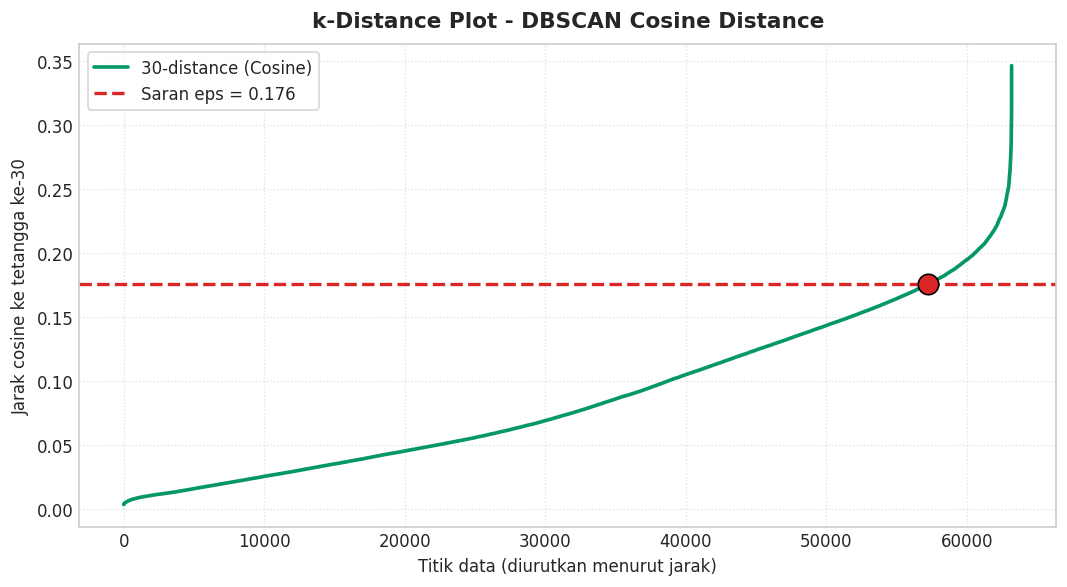

In [ ]:
# k-distance plot untuk menentukan eps (pengganti Elbow Method)
MIN_PTS = 2 * X_sample.shape[1]   # heuristik: 2 x jumlah fitur
print(f"[PARAM] MinPts = {MIN_PTS}")

_log("Menghitung k-distance (satu kali lewat seluruh data, bisa beberapa menit)...")
k_dist = np.sort(kdistance(X_sample, METRIC, MIN_PTS, verbose=len(X_sample) > 50000))
_log("k-distance selesai.")

def find_knee_point(y_vals):
    x = np.arange(len(y_vals), dtype=float)
    xn = (x - x.min()) / (x.max() - x.min())
    yn = (y_vals - y_vals.min()) / (y_vals.max() - y_vals.min())
    p1 = np.array([xn[0], yn[0]])
    line_unit = np.array([xn[-1], yn[-1]]) - p1
    line_unit = line_unit / np.linalg.norm(line_unit)
    pts = np.column_stack([xn, yn]) - p1
    proj = np.outer(pts @ line_unit, line_unit)
    return int(np.argmax(np.linalg.norm(pts - proj, axis=1)))

knee_idx = find_knee_point(k_dist)
eps_suggest = float(k_dist[knee_idx])
print(f"[K-DIST] Saran eps dari siku kurva: {eps_suggest:.4f}")
for q in [50, 75, 90, 95, 99]:
    print(f"[K-DIST] Persentil ke-{q}: {np.percentile(k_dist, q):.4f}")

plt.figure(figsize=(9, 5))
plt.plot(k_dist, linewidth=2.2, color='#059669', label=f'{MIN_PTS}-distance (Cosine)')
plt.axhline(eps_suggest, color='#DC2626', linestyle='--', linewidth=2, label=f'Saran eps = {eps_suggest:.3f}')
plt.scatter([knee_idx], [eps_suggest], color='#DC2626', s=150, zorder=5, edgecolor='black')
plt.title('k-Distance Plot - DBSCAN Cosine Distance', fontsize=13, fontweight='bold', pad=10)
plt.xlabel('Titik data (diurutkan menurut jarak)')
plt.ylabel(f'Jarak cosine ke tetangga ke-{MIN_PTS}')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, facecolor='white')
plt.tight_layout()

kdist_path = os.path.join(OUTPUT_DIR, "kdistance_cosine.png")
plt.savefig(kdist_path, dpi=300)
print(f"[SIMPAN] Grafik k-distance disimpan ke: '{kdist_path}'")
plt.show()

In [ ]:
# class DBSCAN Cosine (implementasi manual, hemat memori)
class DBSCANCosine:
    """
    Sama seperti versi sebelumnya (definisi DBSCAN asli), bedanya daftar tetangga TIDAK disimpan.
      1) Titik core ditentukan dengan menghitung jumlah tetangga per potongan baris.
      2) Klaster diperluas per 'gelombang': tetangga dari sekumpulan titik core dicari langsung dengan
         menghitung jarak ke titik yang belum punya klaster saja (makin lama makin sedikit).
    N_eps(p) = { q | 1 - cos(p, q) <= eps }, termasuk p sendiri. Memori O(n), bukan O(n^2).
    """
    def __init__(self, eps=0.5, min_pts=5, chunk_size=CHUNK_SIZE):
        self.eps = eps
        self.min_pts = min_pts
        self.chunk_size = chunk_size
        self.metric = METRIC
        self.labels_ = None
        self.core_sample_mask_ = None
        self.n_clusters_ = 0
        self.n_noise_ = 0
        self.execution_time_ = 0.0

    def fit(self, X, counts=None, verbose=False):
        start = time.perf_counter()
        n = X.shape[0]
        if counts is None:   # kalau sudah dihitung di luar (dipakai saat uji banyak eps), tidak dihitung ulang
            if verbose:
                _log("  tahap 1/2: hitung jumlah tetangga tiap titik")
            counts = hitung_tetangga(X, self.metric, [self.eps], self.chunk_size, verbose=verbose)[0]
        is_core = counts >= self.min_pts

        if verbose:
            _log(f"  tahap 2/2: perluas klaster ({int(is_core.sum())} titik core)")
        thr = _ambang(self.eps, self.metric)
        labels = np.full(n, -1, dtype=np.int32)   # -1 = noise / belum punya klaster
        cluster_id = 0
        for p in np.where(is_core)[0]:
            if labels[p] != -1:
                continue
            labels[p] = cluster_id
            frontier = np.array([p])
            while len(frontier) > 0:
                cand = np.where(labels == -1)[0]          # hanya titik yang belum punya klaster
                if len(cand) == 0:
                    break
                Xc = X[cand]
                Bc_sq = (Xc * Xc).sum(axis=1) if self.metric == 'euclidean' else None
                hit = np.zeros(len(cand), dtype=bool)
                for s in range(0, len(frontier), self.chunk_size):
                    f = frontier[s:s + self.chunk_size]
                    d = _blok_jarak(X[f], Xc, self.metric, Bc_sq)
                    hit |= (d <= thr).any(axis=0)
                baru = cand[hit]
                labels[baru] = cluster_id                  # core maupun border masuk klaster ini
                frontier = baru[is_core[baru]]             # hanya core baru yang ikut memperluas
            cluster_id += 1

        self.labels_ = labels.astype(int)
        self.core_sample_mask_ = is_core
        self.n_clusters_ = cluster_id
        self.n_noise_ = int(np.sum(labels == -1))
        self.execution_time_ = float(time.perf_counter() - start)
        return self

print("[INFO] Kelas DBSCANCosine berhasil diinisialisasi.")

[INFO] Kelas DBSCANCosine berhasil diinisialisasi.


In [ ]:
# uji validasi terhadap DBSCAN sklearn (pada subset, karena sklearn menyimpan daftar tetangga)
rng_v = np.random.RandomState(RANDOM_STATE)
n_v = min(N_VALIDASI, len(X_sample))
X_val = X_sample[np.sort(rng_v.choice(len(X_sample), size=n_v, replace=False))]

kd_val = kdistance(X_val, METRIC, MIN_PTS)
EPS_TEST = round(float(np.percentile(kd_val, 70)), 4)

mine = DBSCANCosine(eps=EPS_TEST, min_pts=MIN_PTS).fit(X_val)
ref = DBSCAN(eps=EPS_TEST, min_samples=MIN_PTS, metric=METRIC, algorithm='brute').fit(X_val)

ref_core = np.zeros(len(X_val), dtype=bool)
ref_core[ref.core_sample_indices_] = True

print(f"[VALIDASI] subset {n_v} titik | eps = {EPS_TEST:.4f} | MinPts = {MIN_PTS}")
print(f"[VALIDASI] Manual : {mine.n_clusters_} klaster, {mine.n_noise_} noise, {mine.execution_time_:.2f} detik")
print(f"[VALIDASI] sklearn: {len(set(ref.labels_)) - (1 if -1 in ref.labels_ else 0)} klaster, {int(np.sum(ref.labels_ == -1))} noise")
print(f"[VALIDASI] Core point identik : {np.array_equal(mine.core_sample_mask_, ref_core)}")
print(f"[VALIDASI] Noise identik      : {np.array_equal(mine.labels_ == -1, ref.labels_ == -1)}")
print(f"[VALIDASI] Adjusted Rand Index (semua titik)  : {adjusted_rand_score(ref.labels_, mine.labels_):.4f}")
print(f"[VALIDASI] Adjusted Rand Index (hanya core)   : {adjusted_rand_score(ref.labels_[ref_core], mine.labels_[ref_core]):.4f}")
# Catatan: titik border yang berada di antara dua klaster boleh masuk klaster mana saja (sifat DBSCAN),
# jadi ARI semua titik bisa sedikit di bawah 1 walaupun core dan noise identik.

[VALIDASI] subset 10000 titik | eps = 0.2350 | MinPts = 30
[VALIDASI] Manual : 1 klaster, 307 noise, 0.36 detik
[VALIDASI] sklearn: 1 klaster, 307 noise
[VALIDASI] Core point identik : True
[VALIDASI] Noise identik      : True
[VALIDASI] Adjusted Rand Index (semua titik)  : 1.0000
[VALIDASI] Adjusted Rand Index (hanya core)   : 1.0000


In [ ]:
# uji beberapa nilai eps
eps_candidates = sorted(set(round(float(np.percentile(k_dist, q)), 4) for q in [50, 60, 70, 80, 90, 95]) | {round(eps_suggest, 4)})
rows = []

_log(f"Menghitung jumlah tetangga untuk {len(eps_candidates)} nilai eps sekaligus (satu kali lewat data)...")
t0 = time.perf_counter()
counts_all = hitung_tetangga(X_sample, METRIC, eps_candidates, verbose=len(X_sample) > 50000)
t_hitung = time.perf_counter() - t0
_log(f"Selesai dalam {t_hitung:.1f} detik. Sekarang perluas klaster untuk tiap eps.")

for i, eps in enumerate(eps_candidates):
    m = DBSCANCosine(eps=eps, min_pts=MIN_PTS).fit(X_sample, counts=counts_all[i])
    lab = m.labels_
    mk = lab != -1
    largest = np.bincount(lab[mk]).max() / len(lab) * 100 if m.n_clusters_ > 0 else 0.0

    sil = silhouette_aman(X_sample[mk], lab[mk]) if m.n_clusters_ >= 2 else np.nan

    rows.append({
        'eps': eps,
        'Jumlah Klaster': m.n_clusters_,
        'Noise (n)': m.n_noise_,
        'Noise (%)': round(m.n_noise_ / len(lab) * 100, 2),
        'Klaster Terbesar (%)': round(largest, 2),
        'Core Point (n)': int(m.core_sample_mask_.sum()),
        'Silhouette (non-noise)': round(sil, 4) if not np.isnan(sil) else np.nan,
        'Waktu (s)': round(m.execution_time_ + t_hitung / len(eps_candidates), 2)   # perluasan klaster + bagian dari hitung tetangga bersama
    })
    print(f"[SWEEP] eps={eps} -> {m.n_clusters_} klaster, noise {m.n_noise_ / len(lab) * 100:.2f}%")

sweep_df = pd.DataFrame(rows)
print("\n" + "=" * 100)
print("TABEL UJI EPS - DBSCAN COSINE")
print("=" * 100)
print(sweep_df.to_string(index=False))

sweep_path = os.path.join(OUTPUT_DIR, "eps_sweep_cosine.csv")
sweep_df.to_csv(sweep_path, index=False)
print(f"[SIMPAN] Tabel uji eps disimpan ke: '{sweep_path}'")

[07:36:23] Menghitung jumlah tetangga untuk 7 nilai eps sekaligus (satu kali lewat data)...
[07:36:24]   hitung tetangga: potongan 1/158
[07:36:27]   hitung tetangga: potongan 16/158
[07:36:30]   hitung tetangga: potongan 31/158
[07:36:33]   hitung tetangga: potongan 46/158
[07:36:37]   hitung tetangga: potongan 61/158
[07:36:40]   hitung tetangga: potongan 76/158
[07:36:43]   hitung tetangga: potongan 91/158
[07:36:46]   hitung tetangga: potongan 106/158
[07:36:51]   hitung tetangga: potongan 121/158
[07:36:53]   hitung tetangga: potongan 136/158
[07:36:56]   hitung tetangga: potongan 151/158
[07:36:58] Selesai dalam 34.5 detik. Sekarang perluas klaster untuk tiap eps.
[SWEEP] eps=0.0743 -> 184 klaster, noise 32.37%
[SWEEP] eps=0.0969 -> 163 klaster, noise 22.02%
[SWEEP] eps=0.1214 -> 88 klaster, noise 11.70%
[SWEEP] eps=0.1458 -> 12 klaster, noise 4.21%
[SWEEP] eps=0.1739 -> 2 klaster, noise 0.77%
[SWEEP] eps=0.1759 -> 2 klaster, noise 0.65%
[SWEEP] eps=0.1951 -> 1 klaster, noise 0.1

In [ ]:
# model final, evaluasi, profil klaster, simpan hasil
EPS_MANUAL = None   # isi angka jika mau menentukan eps sendiri (lihat tabel sel uji eps)

ok = sweep_df[(sweep_df['Jumlah Klaster'] >= 2) & (sweep_df['Noise (%)'] <= 30)]
if EPS_MANUAL is not None:
    EPS_FINAL = float(EPS_MANUAL)
elif len(ok) > 0:
    EPS_FINAL = float(ok.sort_values('Silhouette (non-noise)', ascending=False).iloc[0]['eps'])
else:
    EPS_FINAL = float(eps_suggest)
print(f"[FINAL] eps = {EPS_FINAL} | MinPts = {MIN_PTS}")

_log("Menjalankan model final (waktu eksekusi dihitung penuh: hitung tetangga + perluasan klaster)...")
model_dbscan = DBSCANCosine(eps=EPS_FINAL, min_pts=MIN_PTS).fit(X_sample, verbose=len(X_sample) > 50000)
labels = model_dbscan.labels_
mask = labels != -1
n_total = len(labels)

if model_dbscan.n_clusters_ >= 2:
    sil_score = silhouette_aman(X_sample[mask], labels[mask])
    db_score = float(davies_bouldin_score(X_sample[mask], labels[mask]))
    ch_score = float(calinski_harabasz_score(X_sample[mask], labels[mask]))
else:
    sil_score = db_score = ch_score = np.nan

sizes = np.bincount(labels[mask]) if model_dbscan.n_clusters_ > 0 else np.array([0])

eval_df = pd.DataFrame([{
    'Distance Metric': 'Cosine  Distance',
    'eps': EPS_FINAL,
    'MinPts': MIN_PTS,
    'Jumlah Data Dipakai': n_total,
    'Jumlah Fitur': X_sample.shape[1],
    'Jumlah Klaster': model_dbscan.n_clusters_,
    'Klaster >=1% data': int(np.sum(sizes >= 0.01 * n_total)),
    'Noise (n)': model_dbscan.n_noise_,
    'Noise (%)': round(model_dbscan.n_noise_ / n_total * 100, 2),
    'Core Point (n)': int(model_dbscan.core_sample_mask_.sum()),
    'Silhouette Score (non-noise) (↑)': round(sil_score, 4),
    'Davies–Bouldin Index (non-noise) (↓)': round(db_score, 4),
    'Calinski–Harabasz Index (non-noise) (↑)': round(ch_score, 2),
    'Execution Time (s) (↓)': round(model_dbscan.execution_time_, 5),
    'Ukuran Sampel Silhouette': int(min(SIL_SAMPLE, int(mask.sum())))
}])

print("\n" + "=" * 80)
print("TABEL EVALUASI DBSCAN COSINE")
print("=" * 80)
print(eval_df.T.to_string(header=False))
print("=" * 80)

df_result = df_sample.copy()
df_result['Cluster_DBSCAN'] = labels
df_result[LABEL] = y_sample.values

profil = df_result.groupby('Cluster_DBSCAN').mean().round(3)
profil.insert(0, 'Jumlah Data', df_result.groupby('Cluster_DBSCAN').size())
profil['% Diabetes'] = df_result.groupby('Cluster_DBSCAN')[LABEL].apply(lambda s: (s == 1).mean() * 100).round(2)

excel_path = os.path.join(OUTPUT_DIR, "evaluasi_dbscan_cosine.xlsx")
with pd.ExcelWriter(excel_path, engine='openpyxl') as writer:
    eval_df.to_excel(writer, sheet_name='Ringkasan_Evaluasi', index=False)
    profil.to_excel(writer, sheet_name='Profil_Klaster')
print(f"[SIMPAN] Evaluasi & profil klaster disimpan ke: '{excel_path}'")

csv_path = os.path.join(OUTPUT_DIR, "data_terklaster_dbscan_cosine.csv")
df_result.to_csv(csv_path, index=False)
print(f"[SIMPAN] Data terklaster disimpan ke: '{csv_path}'")

[FINAL] eps = 0.0969 | MinPts = 30
[07:37:36] Menjalankan model final (waktu eksekusi dihitung penuh: hitung tetangga + perluasan klaster)...
[07:37:36]   tahap 1/2: hitung jumlah tetangga tiap titik
[07:37:36]   hitung tetangga: potongan 1/158
[07:37:38]   hitung tetangga: potongan 16/158
[07:37:39]   hitung tetangga: potongan 31/158
[07:37:41]   hitung tetangga: potongan 46/158
[07:37:42]   hitung tetangga: potongan 61/158
[07:37:43]   hitung tetangga: potongan 76/158
[07:37:44]   hitung tetangga: potongan 91/158
[07:37:46]   hitung tetangga: potongan 106/158
[07:37:47]   hitung tetangga: potongan 121/158
[07:37:48]   hitung tetangga: potongan 136/158
[07:37:49]   hitung tetangga: potongan 151/158
[07:37:50]   tahap 2/2: perluas klaster (37911 titik core)

TABEL EVALUASI DBSCAN COSINE
Distance Metric                          Cosine  Distance
eps                                                0.0969
MinPts                                                 30
Jumlah Data Dipakai         

In [ ]:
# profil tiap klaster (label -1 = noise)
profil

,Jumlah Data,HighBP,HighChol,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Diabetes_binary,% Diabetes
Cluster_DBSCAN,,,,,,,,,,,,,,,,,,
-1,13915,0.563,0.503,31.519,0.530,0.141,0.266,0.537,0.513,0.625,3.433,7.976,12.283,0.520,0.470,8.977,0.625,62.49
0,8609,0.158,0.160,27.896,0.319,0.000,0.000,0.998,0.834,1.000,2.231,2.823,2.080,0.001,0.261,6.973,0.244,24.37
1,860,1.000,1.000,29.966,1.000,0.000,0.000,1.000,1.000,1.000,2.728,1.857,3.328,0.000,1.000,9.326,0.612,61.16
2,511,0.000,1.000,28.029,1.000,0.000,0.000,1.000,1.000,1.000,2.350,1.012,1.262,0.000,1.000,8.589,0.382,38.16
3,196,0.000,0.000,27.204,1.000,0.000,0.000,0.000,1.000,1.000,2.454,0.750,0.980,0.000,1.000,7.923,0.306,30.61
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
158,30,0.000,0.000,27.433,1.000,0.000,0.000,0.000,1.000,1.000,2.800,0.833,2.867,1.000,0.000,11.033,0.367,36.67
159,36,1.000,0.000,33.972,1.000,0.000,0.000,0.000,1.000,1.000,3.250,0.583,1.806,1.000,1.000,10.583,0.861,86.11
160,22,1.000,0.000,31.864,0.000,0.000,0.000,0.000,0.000,0.000,4.045,3.136,16.318,1.000,0.000,10.045,0.727,72.73


[SIMPAN] Grafik pemetaan klaster disimpan ke: '/content/drive/MyDrive/ml-sem5/kuis1/outputDBSCAN/cluster_dbscan_cosine.png'


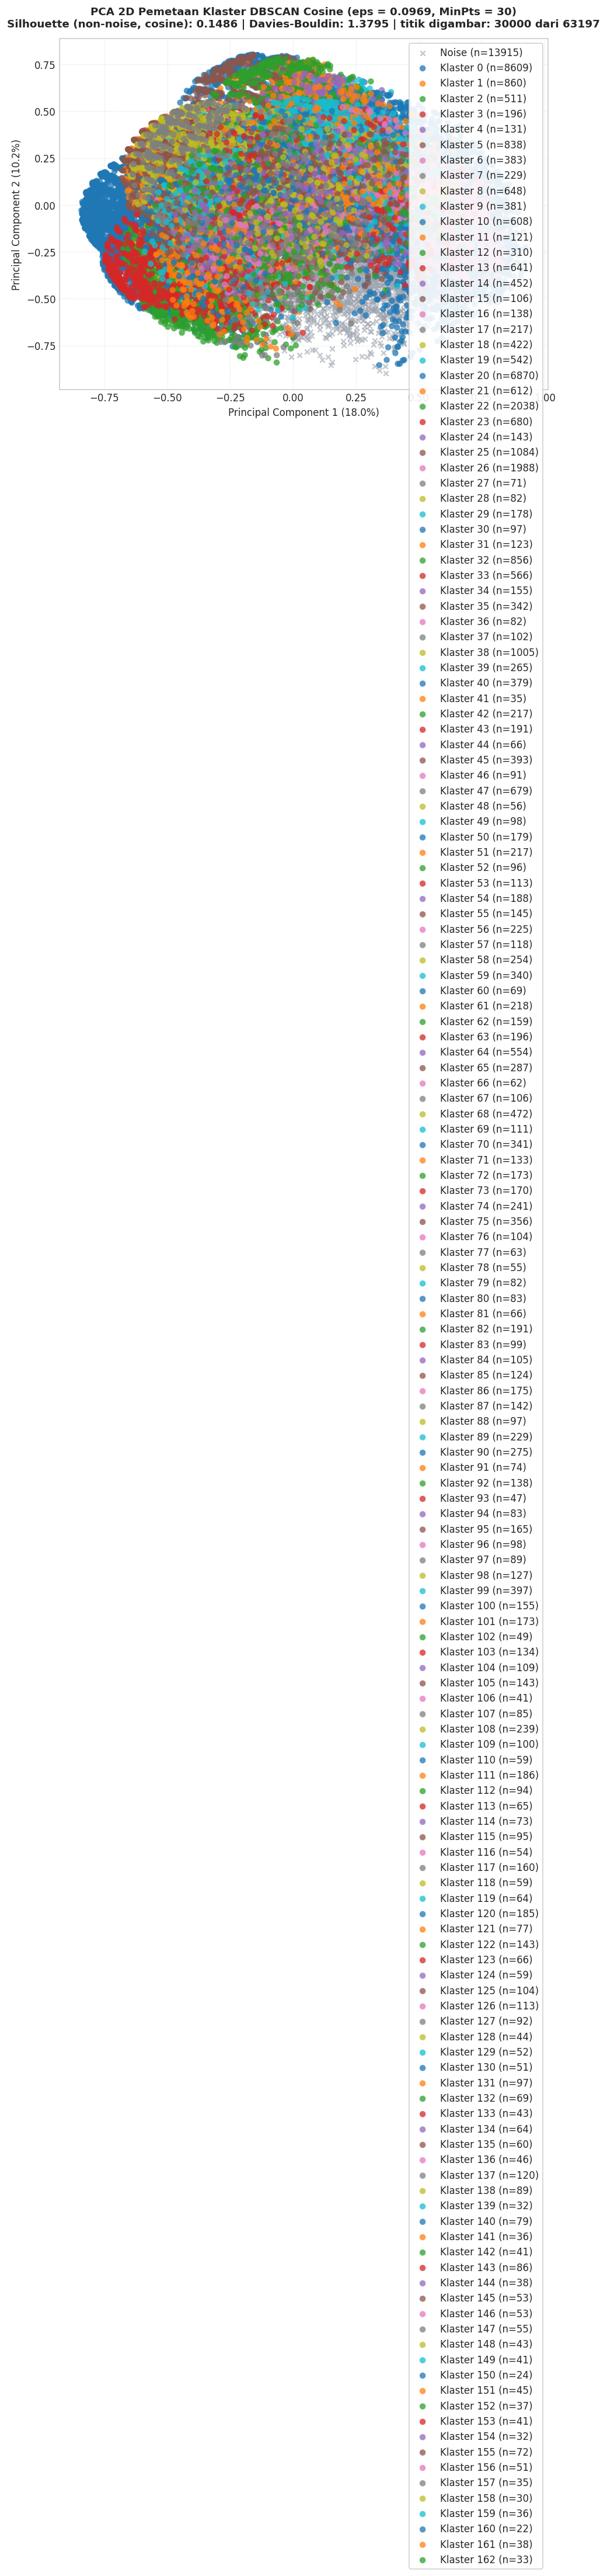

In [ ]:
# visualisasi PCA 2D pemetaan klaster
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_sample)

# gambar hanya PLOT_N titik acak supaya ringan; hitungan n di legenda tetap dari SEMUA data
if len(X_sample) > PLOT_N:
    idx_plot = np.sort(np.random.RandomState(RANDOM_STATE).choice(len(X_sample), size=PLOT_N, replace=False))
else:
    idx_plot = np.arange(len(X_sample))
Xp, lp = X_pca[idx_plot], labels[idx_plot]

plt.figure(figsize=(9, 6.5))
n_cl = model_dbscan.n_clusters_
palette = sns.color_palette("tab10", max(n_cl, 1))

m_noise = lp == -1
plt.scatter(Xp[m_noise, 0], Xp[m_noise, 1], c='#9CA3AF', marker='x', s=25, alpha=0.6,
            label=f'Noise (n={(labels == -1).sum()})')
for k in range(n_cl):
    mk = lp == k
    plt.scatter(Xp[mk, 0], Xp[mk, 1], color=palette[k % len(palette)], s=40, alpha=0.75, edgecolors='none',
                label=f'Klaster {k} (n={(labels == k).sum()})')

plt.title(f'PCA 2D Pemetaan Klaster DBSCAN Cosine (eps = {EPS_FINAL}, MinPts = {MIN_PTS})\n'
          f'Silhouette (non-noise, cosine): {sil_score:.4f} | Davies-Bouldin: {db_score:.4f} | titik digambar: {len(idx_plot)} dari {len(X_sample)}',
          fontsize=11, fontweight='bold', pad=12)
plt.xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)')
plt.ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, facecolor='white', framealpha=0.9, loc='best')
plt.tight_layout()

cluster_path = os.path.join(OUTPUT_DIR, "cluster_dbscan_cosine.png")
plt.savefig(cluster_path, dpi=300)
print(f"[SIMPAN] Grafik pemetaan klaster disimpan ke: '{cluster_path}'")
plt.show()


In [ ]:
# fitur paling berpengaruh di PC1 & PC2
loadings = pd.DataFrame(pca.components_.T, index=df_features.columns, columns=['PC1', 'PC2'])
print("Fitur paling berpengaruh di PC1:")
print(loadings['PC1'].abs().sort_values(ascending=False).head(6).round(3))
print("\nFitur paling berpengaruh di PC2:")
print(loadings['PC2'].abs().sort_values(ascending=False).head(6).round(3))


Fitur paling berpengaruh di PC1:
GenHlth         0.428
DiffWalk        0.395
HighBP          0.371
PhysHlth        0.332
HighChol        0.294
PhysActivity    0.273
Name: PC1, dtype: float64

Fitur paling berpengaruh di PC2:
Age             0.470
Fruits          0.425
HighBP          0.399
HighChol        0.373
Veggies         0.288
PhysActivity    0.264
Name: PC2, dtype: float64


In [ ]:
# klaster vs label diabetes (pembanding)
label_vs = pd.crosstab(df_result['Cluster_DBSCAN'], df_result[LABEL])
label_vs.columns = ['Tidak Diabetes (0)' if c == 0 else 'Diabetes (1)' for c in label_vs.columns]
label_vs['Total'] = label_vs.sum(axis=1)
if 'Diabetes (1)' in label_vs.columns:
    label_vs['Diabetes (%)'] = (label_vs['Diabetes (1)'] / label_vs['Total'] * 100).round(2)
print(f"Proporsi diabetes seluruh sampel = {(y_sample == 1).mean() * 100:.2f}%")
print(label_vs.to_string())

if model_dbscan.n_clusters_ >= 2:
    ari = adjusted_rand_score(y_sample.values[mask], labels[mask])
    print(f"\nARI klaster vs label (non-noise): {ari:.4f}")
diab_noise = int(((labels == -1) & (y_sample.values == 1)).sum())
print(f"Diabetes di noise: {diab_noise} dari {int((y_sample == 1).sum())}")

Proporsi diabetes seluruh sampel = 52.71%
                Tidak Diabetes (0)  Diabetes (1)  Total  Diabetes (%)
Cluster_DBSCAN                                                       
-1                            5219          8696  13915         62.49
 0                            6511          2098   8609         24.37
 1                             334           526    860         61.16
 2                             316           195    511         38.16
 3                             136            60    196         30.61
 4                              39            92    131         70.23
 5                             351           487    838         58.11
 6                             244           139    383         36.29
 7                              76           153    229         66.81
 8                             441           207    648         31.94
 9                             119           262    381         68.77
 10                            468           140